<a href="https://colab.research.google.com/github/vn322/gtsolifk/blob/main/%D0%B0%D0%BA%D1%82%D0%B8%D0%B2%D0%BD%D0%BE%D1%81%D1%82%D1%8C.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [12]:
import numpy as np
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score



df = pd.read_excel('/content/vyatkin_Sorevnovatelnaya_deyatelnost_logregressia.xlsx')


# Зануляем удары для минут, которые превышают фактическое время боя (time)
for i in range(1, 6):
    df.loc[df['time'] < i, f'Ht{i}'] = 0
    df.loc[df['time'] < i, f'Kt{i}'] = 0

# Рассчитываем общую активность для генерации логичного исхода (result)
total_punches = df[[f'Ht{i}' for i in range(1, 6)]].sum(axis=1)
total_kicks = df[[f'Kt{i}' for i in range(1, 6)]].sum(axis=1)
# Удары ногами (эффект нокаута) весят чуть больше в симуляции победы
score = total_punches * 0.4 + total_kicks * 0.7
df['result'] = (score > score.median()).astype(int)

# ==========================================
# 2. РАЗВЕДОЧНЫЙ АНАЛИЗ ДАННЫХ (EDA)
# ==========================================
print("--- ОБЩАЯ СТАТИСТИКА ПО ДАТАСЕТУ ---")
print(df.groupby('sport')['result'].mean().to_string())
print("\nСредний вес спортсменов:", round(df['weight'].mean(), 2), "кг")


# Создаем агрегированные фичи для более стабильного анализа в подгруппах
df['Total_Ht'] = df[[f'Ht{i}' for i in range(1, 6)]].sum(axis=1)
df['Total_Kt'] = df[[f'Kt{i}' for i in range(1, 6)]].sum(axis=1)

# ==========================================
# 3. ФУНКЦИЯ ОЦЕНКИ И ИНТЕРПРЕТАЦИИ МОДЕЛЕЙ
# ==========================================
features = [f'Ht{i}' for i in range(1, 6)] + [f'Kt{i}' for i in range(1, 6)] + ['weight', 'time']

def evaluate_logistic_model(data, title):
    print(f"\n{'='*40}\nМОДЕЛЬ: {title} (Размер выборки: {len(data)})\n{'='*40}")

    X = data[features]
    y = data['result']

    # Проверка на сбалансированность классов
    if len(y.unique()) < 2:
        print("Ошибка: В подвыборке представлен только один класс исхода.")
        return

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

    # Масштабирование признаков (важно для корректного сравнения весов коэффициентов)
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train_scaled, y_train)

    # Предсказания
    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    # Расчет критериев продуктивности
    print("Критерии продуктивности (Тестовая выборка):")
    print(f"  Accuracy  (Доля правильных ответов): {accuracy_score(y_test, y_pred):.3f}")
    print(f"  Precision (Точность):                 {precision_score(y_test, y_pred):.3f}")
    print(f"  Recall    (Полнота):                  {recall_score(y_test, y_pred):.3f}")
    print(f"  F1-Score  (Баланс точности/полноты):  {f1_score(y_test, y_pred):.3f}")
    print(f"  ROC-AUC   (Качество классификации):   {roc_auc_score(y_test, y_proba):.3f}")

    # Оценка вклада отдельных параметров
    importance = pd.DataFrame({
        'Параметр': features,
        'Коэффициент': model.coef_[0],
        'Абс_Вклад': np.abs(model.coef_[0])
    }).sort_values(by='Абс_Вклад', ascending=False)

    print("\nВклад параметров в успешность боя (топ признаков по абсолютному значению):")
    print(importance[['Параметр', 'Коэффициент']].to_string(index=False))

# ==========================================
# 4. ПОСТРОЕНИЕ ВСЕХ ПЯТИ ВАРИАНТОВ МОДЕЛЕЙ
# ==========================================
# Модель 1: Полный датасет
evaluate_logistic_model(df, "Полный датасет")

# Модель 2: Рукопашный бой
evaluate_logistic_model(df[df['sport'] == 'Рукопашный бой'], "Рукопашный бой (РБ)")

# Модель 3: Армейский рукопашный бой
evaluate_logistic_model(df[df['sport'] == 'Армейский рукопашный бой'], "Армейский рукопашный бой (АРБ)")

# Модель 4: Вес до 80 кг
evaluate_logistic_model(df[df['weight'] <= 80], "Весовая категория до 80 кг")

# Модель 5: Вес больше 80 кг
evaluate_logistic_model(df[df['weight'] > 80], "Весовая категория более 80 кг")
df.drop(columns=["weight", "time", "result"]).describe()


--- ОБЩАЯ СТАТИСТИКА ПО ДАТАСЕТУ ---
sport
Армейский рукопашный бой    0.520000
Рукопашный бой              0.474227

Средний вес спортсменов: 69.57 кг

МОДЕЛЬ: Полный датасет (Размер выборки: 197)
Критерии продуктивности (Тестовая выборка):
  Accuracy  (Доля правильных ответов): 0.883
  Precision (Точность):                 0.848
  Recall    (Полнота):                  0.933
  F1-Score  (Баланс точности/полноты):  0.889
  ROC-AUC   (Качество классификации):   0.986

Вклад параметров в успешность боя (топ признаков по абсолютному значению):
Параметр  Коэффициент
     Kt3     1.589550
     Kt1     1.521845
     Kt4     1.441518
     Ht1     1.428722
     Ht4     1.121811
     Ht3     1.072131
     Ht2     1.038422
     Kt2     0.968947
     Kt5     0.810767
  weight    -0.310284
    time     0.156383
     Ht5    -0.058487

МОДЕЛЬ: Рукопашный бой (РБ) (Размер выборки: 97)
Критерии продуктивности (Тестовая выборка):
  Accuracy  (Доля правильных ответов): 1.000
  Precision (Точность):     

,Ht1,Ht2,Ht3,Ht4,Ht5,Kt1,Kt2,Kt3,Kt4,Kt5,Total_Ht,Total_Kt
count,197.000000,197.000000,197.000000,197.000000,197.000000,197.000000,197.000000,197.000000,197.000000,197.000000,197.000000,197.000000
mean,4.360406,3.786802,3.908629,1.649746,0.964467,3.147208,2.340102,2.010152,1.177665,0.543147,14.670051,9.218274
std,3.411723,2.823955,3.319973,2.429446,1.964937,2.337288,1.995164,1.870801,1.785402,1.255362,9.224400,6.344536
min,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,2.000000,2.000000,1.000000,0.000000,0.000000,1.000000,1.000000,0.000000,0.000000,0.000000,8.000000,5.000000
50%,4.000000,3.000000,3.000000,0.000000,0.000000,3.000000,2.000000,2.000000,0.000000,0.000000,13.000000,8.000000
75%,6.000000,6.000000,6.000000,3.000000,1.000000,4.000000,3.000000,3.000000,2.000000,0.000000,20.000000,13.000000
max,18.000000,13.000000,16.000000,10.000000,11.000000,12.000000,11.000000,8.000000,8.000000,7.000000,54.000000,31.000000


--- 2.1. ОПИСАТЕЛЬНАЯ СТАТИСТИКА АКТИВНОСТИ ---
              Ht1         Ht2         Ht3         Ht4         Ht5         Kt1  \
count  197.000000  197.000000  197.000000  197.000000  197.000000  197.000000   
mean     4.360406    3.786802    3.908629    1.680203    0.969543    3.147208   
std      3.411723    2.823955    3.319973    2.446210    1.963724    2.337288   
min      0.000000    0.000000    0.000000    0.000000    0.000000    0.000000   
25%      2.000000    2.000000    1.000000    0.000000    0.000000    1.000000   
50%      4.000000    3.000000    3.000000    0.000000    0.000000    3.000000   
75%      6.000000    6.000000    6.000000    3.000000    1.000000    4.000000   
max     18.000000   13.000000   16.000000   10.000000   11.000000   12.000000   

              Kt2         Kt3         Kt4         Kt5    Total_Ht    Total_Kt  \
count  197.000000  197.000000  197.000000  197.000000  197.000000  197.000000   
mean     2.340102    2.010152    1.203046    0.568528   14.7

/tmp/ipykernel_1260/2359062935.py:92: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='sport', y='Total_Activity', palette='Set2')
/tmp/ipykernel_1260/2359062935.py:97: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='sport', y='Total_Activity', palette='Set2', inner='quartile')
/tmp/ipykernel_1260/2359062935.py:102: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='weight_cat', y='Total_Activity', palette='Pastel1')
/tmp/ipykernel_1260/2359062935.py:106: FutureWarning: 

Passing `palette` without assigning `hue`

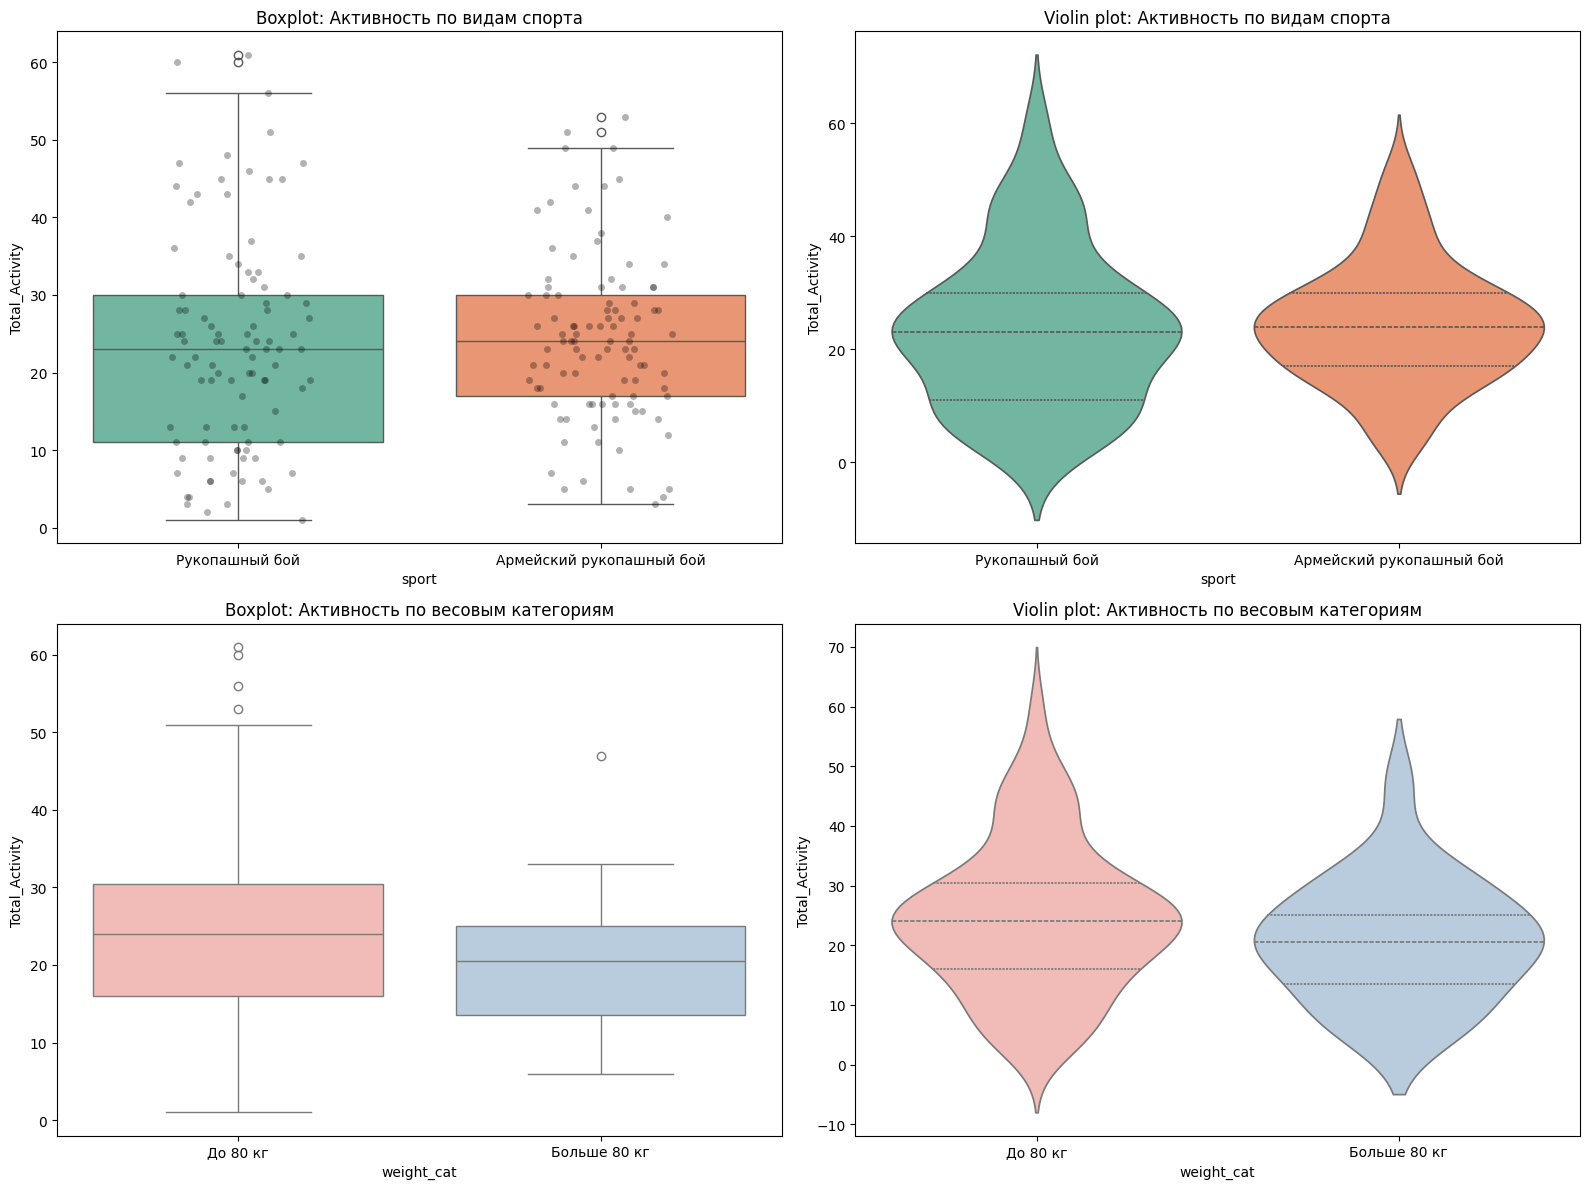


СТАТИСТИЧЕСКАЯ МОДЕЛЬ: Полный датасет (только активность) (N = 197)

Метрики качества модели на тестовой выборке:
Критерий продуктивности  Значение
               Accuracy  0.433333
              Precision  0.437500
                 Recall  0.466667
               F1-Score  0.451613
                ROC-AUC  0.444444

Вклад параметров в успешность боя (отсортировано по силе влияния):
Минутный параметр активности  Коэффициент регрессии (Log Odds)  Отношение шансов (Odds Ratio)
                         Kt5                         -0.542006                       0.581580
                         Kt4                          0.508380                       1.662595
                         Ht4                         -0.405394                       0.666714
                         Ht2                          0.364296                       1.439501
                         Kt1                          0.313166                       1.367749
                         Ht5                     

In [11]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# ==========================================
# 1. ЗАГРУЗКА И ПОДГОТОВКА ДАННЫХ
# ==========================================
# Укажите путь к вашему файлу (поддерживаются .csv, .xlsx, .tsv и т.д.)
# Примеры: pd.read_excel('data.xlsx') или pd.read_csv('data.csv', sep=';')

df = pd.read_excel('/content/vyatkin_Sorevnovatelnaya_deyatelnost_logregressia.xlsx')

# Списки колонок активности для удобства фильтрации
ht_cols = [f'Ht{i}' for i in range(1, 6)]
kt_cols = [f'Kt{i}' for i in range(1, 6)]
activity_features = ht_cols + kt_cols

# Рассчитываем суммарные показатели для комплексного анализа распределений
df['Total_Ht'] = df[ht_cols].sum(axis=1)
df['Total_Kt'] = df[kt_cols].sum(axis=1)
df['Total_Activity'] = df['Total_Ht'] + df['Total_Kt']

# ==========================================
# 2. ПОЛНЫЙ СТАТИСТИЧЕСКИЙ АНАЛИЗ (EDA)
# ==========================================
print("--- 2.1. ОПИСАТЕЛЬНАЯ СТАТИСТИКА АКТИВНОСТИ ---")
# Вывод сводной таблицы штатными средствами pandas
print(df[activity_features + ['Total_Ht', 'Total_Kt', 'Total_Activity']].describe())

print("\n--- 2.2. ПРОВЕРКА РАСПРЕДЕЛЕНИЙ НА НОРМАЛЬНОСТЬ (Тест Шапиро-Уилка) ---")
# Проверяем суммарную активность
for col in ['Total_Ht', 'Total_Kt', 'Total_Activity']:
    stat, p_val = stats.shapiro(df[col].dropna())
    print(f"Признак: {col:15} | Статистика: {stat:.4f} | p-value: {p_val:.4e} -> {'Нормальное' if p_val > 0.05 else 'НЕ нормальное'}")

print("\n--- 2.3. СРАВНЕНИЕ РАСПРЕДЕЛЕНИЙ ПО ГРУППАМ ---")
# Функция для автоматического выбора статистического теста (Т-тест или Манна-Уитни)
def compare_groups(data, group_col, target_col):
    groups = data[group_col].unique()
    if len(groups) != 2:
        print(f"Группировка по {group_col} невозможна: ожидалось 2 группы, найдено {len(groups)}")
        return
    g1 = data[data[group_col] == groups[0]][target_col].dropna()
    g2 = data[data[group_col] == groups[1]][target_col].dropna()

    # Тест Левена на равенство дисперсий
    levene_p = stats.levene(g1, g2).pvalue
    # Тесты Шапиро на нормальность
    norm_p1 = stats.shapiro(g1).pvalue
    norm_p2 = stats.shapiro(g2).pvalue

    if norm_p1 > 0.05 and norm_p2 > 0.05:
        # Студенческий Т-тест (параметрический)
        stat, p = stats.ttest_ind(g1, g2, equal_var=(levene_p > 0.05))
        test_name = "T-test"
    else:
        # Тест Манна-Уитни (непараметрический)
        stat, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        test_name = "Mann-Whitney U"

    print(f"Различия по {group_col:6} ({groups[0]} vs {groups[1]}) для {target_col}:")
    print(f"  Тест: {test_name} | p-value: {p:.4e} -> {'Различия ЗНАЧИМЫ' if p < 0.05 else 'Различия НЕ значимы'}")

# Разделение по весу на категории до 80 и больше 80 кг
df['weight_cat'] = np.where(df['weight'] <= 80, 'До 80 кг', 'Больше 80 кг')

# Анализируем влияние факторов на общую активность
compare_groups(df, 'sport', 'Total_Activity')
compare_groups(df, 'weight_cat', 'Total_Activity')

# Сравнение для времени боя (если в данных несколько уникальных значений минут, используем Краскела-Уоллиса)
if df['time'].nunique() > 2:
    time_groups = [df[df['time'] == t]['Total_Activity'].dropna() for t in df['time'].unique()]
    stat, p = stats.kruskal(*time_groups)
    print(f"Различия по времени боя (Kruskal-Wallis) для Total_Activity: p-value = {p:.4e}")
else:
    compare_groups(df, 'time', 'Total_Activity')

# ==========================================
# 3. ВИЗУАЛИЗАЦИЯ (БОКСПЛОТЫ И ВАЙОЛИН ПЛОТЫ)
# ==========================================
plt.figure(figsize=(16, 12))

# График 1: Распределение общей активности по видам спорта
plt.subplot(2, 2, 1)
sns.boxplot(data=df, x='sport', y='Total_Activity', palette='Set2')
sns.stripplot(data=df, x='sport', y='Total_Activity', color='black', alpha=0.3, jitter=0.2)
plt.title('Boxplot: Активность по видам спорта')

plt.subplot(2, 2, 2)
sns.violinplot(data=df, x='sport', y='Total_Activity', palette='Set2', inner='quartile')
plt.title('Violin plot: Активность по видам спорта')

# График 2: Распределение общей активности по весовым категориям
plt.subplot(2, 2, 3)
sns.boxplot(data=df, x='weight_cat', y='Total_Activity', palette='Pastel1')
plt.title('Boxplot: Активность по весовым категориям')

plt.subplot(2, 2, 4)
sns.violinplot(data=df, x='weight_cat', y='Total_Activity', palette='Pastel1', inner='quartile')
plt.title('Violin plot: Активность по весовым категориям')

plt.tight_layout()
plt.show()

# ==========================================
# 4. МАТЕМАТИЧЕСКОЕ МОДЕЛИРОВАНИЕ И ОЦЕНКА ВКЛАДА
# ==========================================
def run_logistic_regression(data, title):
    print(f"\n{'='*50}\nСТАТИСТИЧЕСКАЯ МОДЕЛЬ: {title} (N = {len(data)})\n{'='*50}")

    X = data[activity_features]
    y = data['result']

    if len(y.unique()) < 2:
        print("Построение модели невозможно: подвыборка содержит только один класс исхода.")
        return

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

    # Стандартизация исключительно минутных параметров активности
    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    # Вывод метрик эффективности модели
    metrics_df = pd.DataFrame({
        'Критерий продуктивности': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
        'Значение': [
            accuracy_score(y_test, y_pred),
            precision_score(y_test, y_pred),
            recall_score(y_test, y_pred),
            f1_score(y_test, y_pred),
            roc_auc_score(y_test, y_proba)
        ]
    })
    print("\nМетрики качества модели на тестовой выборке:")
    print(metrics_df.to_string(index=False))


    # Оценка вклада отдельных параметров активности
    importance = pd.DataFrame({
        'Минутный параметр активности': activity_features,
        'Коэффициент регрессии (Log Odds)': model.coef_[0],
        'Отношение шансов (Odds Ratio)': np.exp(model.coef_[0]),
        'Абсолютное влияние': np.abs(model.coef_[0])
    }).sort_values(by='Абсолютное влияние', ascending=False)

    print("\nВклад параметров в успешность боя (отсортировано по силе влияния):")
    print(importance[['Минутный параметр активности', 'Коэффициент регрессии (Log Odds)', 'Отношение шансов (Odds Ratio)']].to_string(index=False))

# Запуск 5 целевых конфигураций моделей
run_logistic_regression(df, "Полный датасет (только активность)")
run_logistic_regression(df[df['sport'] == 'Рукопашный бой'], "Рукопашный бой (РБ)")
run_logistic_regression(df[df['sport'] == 'Армейский рукопашный бой'], "Армейский рукопашный бой (АРБ)")
run_logistic_regression(df[df['weight_cat'] == 'До 80 кг'], "Весовая категория до 80 кг")
run_logistic_regression(df[df['weight_cat'] == 'Больше 80 кг'], "Весовая категория более 80 кг")


--- 2.1. ОПИСАТЕЛЬНАЯ СТАТИСТИКА АКТИВНОСТИ ---
              Ht1         Ht2         Ht3         Ht4         Ht5         Kt1  \
count  197.000000  197.000000  197.000000  197.000000  197.000000  197.000000   
mean     4.360406    3.786802    3.908629    1.680203    0.969543    3.147208   
std      3.411723    2.823955    3.319973    2.446210    1.963724    2.337288   
min      0.000000    0.000000    0.000000    0.000000    0.000000    0.000000   
25%      2.000000    2.000000    1.000000    0.000000    0.000000    1.000000   
50%      4.000000    3.000000    3.000000    0.000000    0.000000    3.000000   
75%      6.000000    6.000000    6.000000    3.000000    1.000000    4.000000   
max     18.000000   13.000000   16.000000   10.000000   11.000000   12.000000   

              Kt2         Kt3         Kt4         Kt5    Total_Ht    Total_Kt  \
count  197.000000  197.000000  197.000000  197.000000  197.000000  197.000000   
mean     2.340102    2.010152    1.203046    0.568528   14.7

/tmp/ipykernel_1260/1704891888.py:73: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='sport', y='Total_Activity', palette='Set2', ax=axes[0, 0])
/tmp/ipykernel_1260/1704891888.py:75: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df, x='sport', y='Total_Activity', palette='Set2', inner='quartile', ax=axes[0, 1])
/tmp/ipykernel_1260/1704891888.py:79: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='weight_cat', y='Total_Activity', palette='Pastel1', ax=axes[1, 0])
/tmp/ipykernel_1260/1704891888.py:81: FutureWarning: 

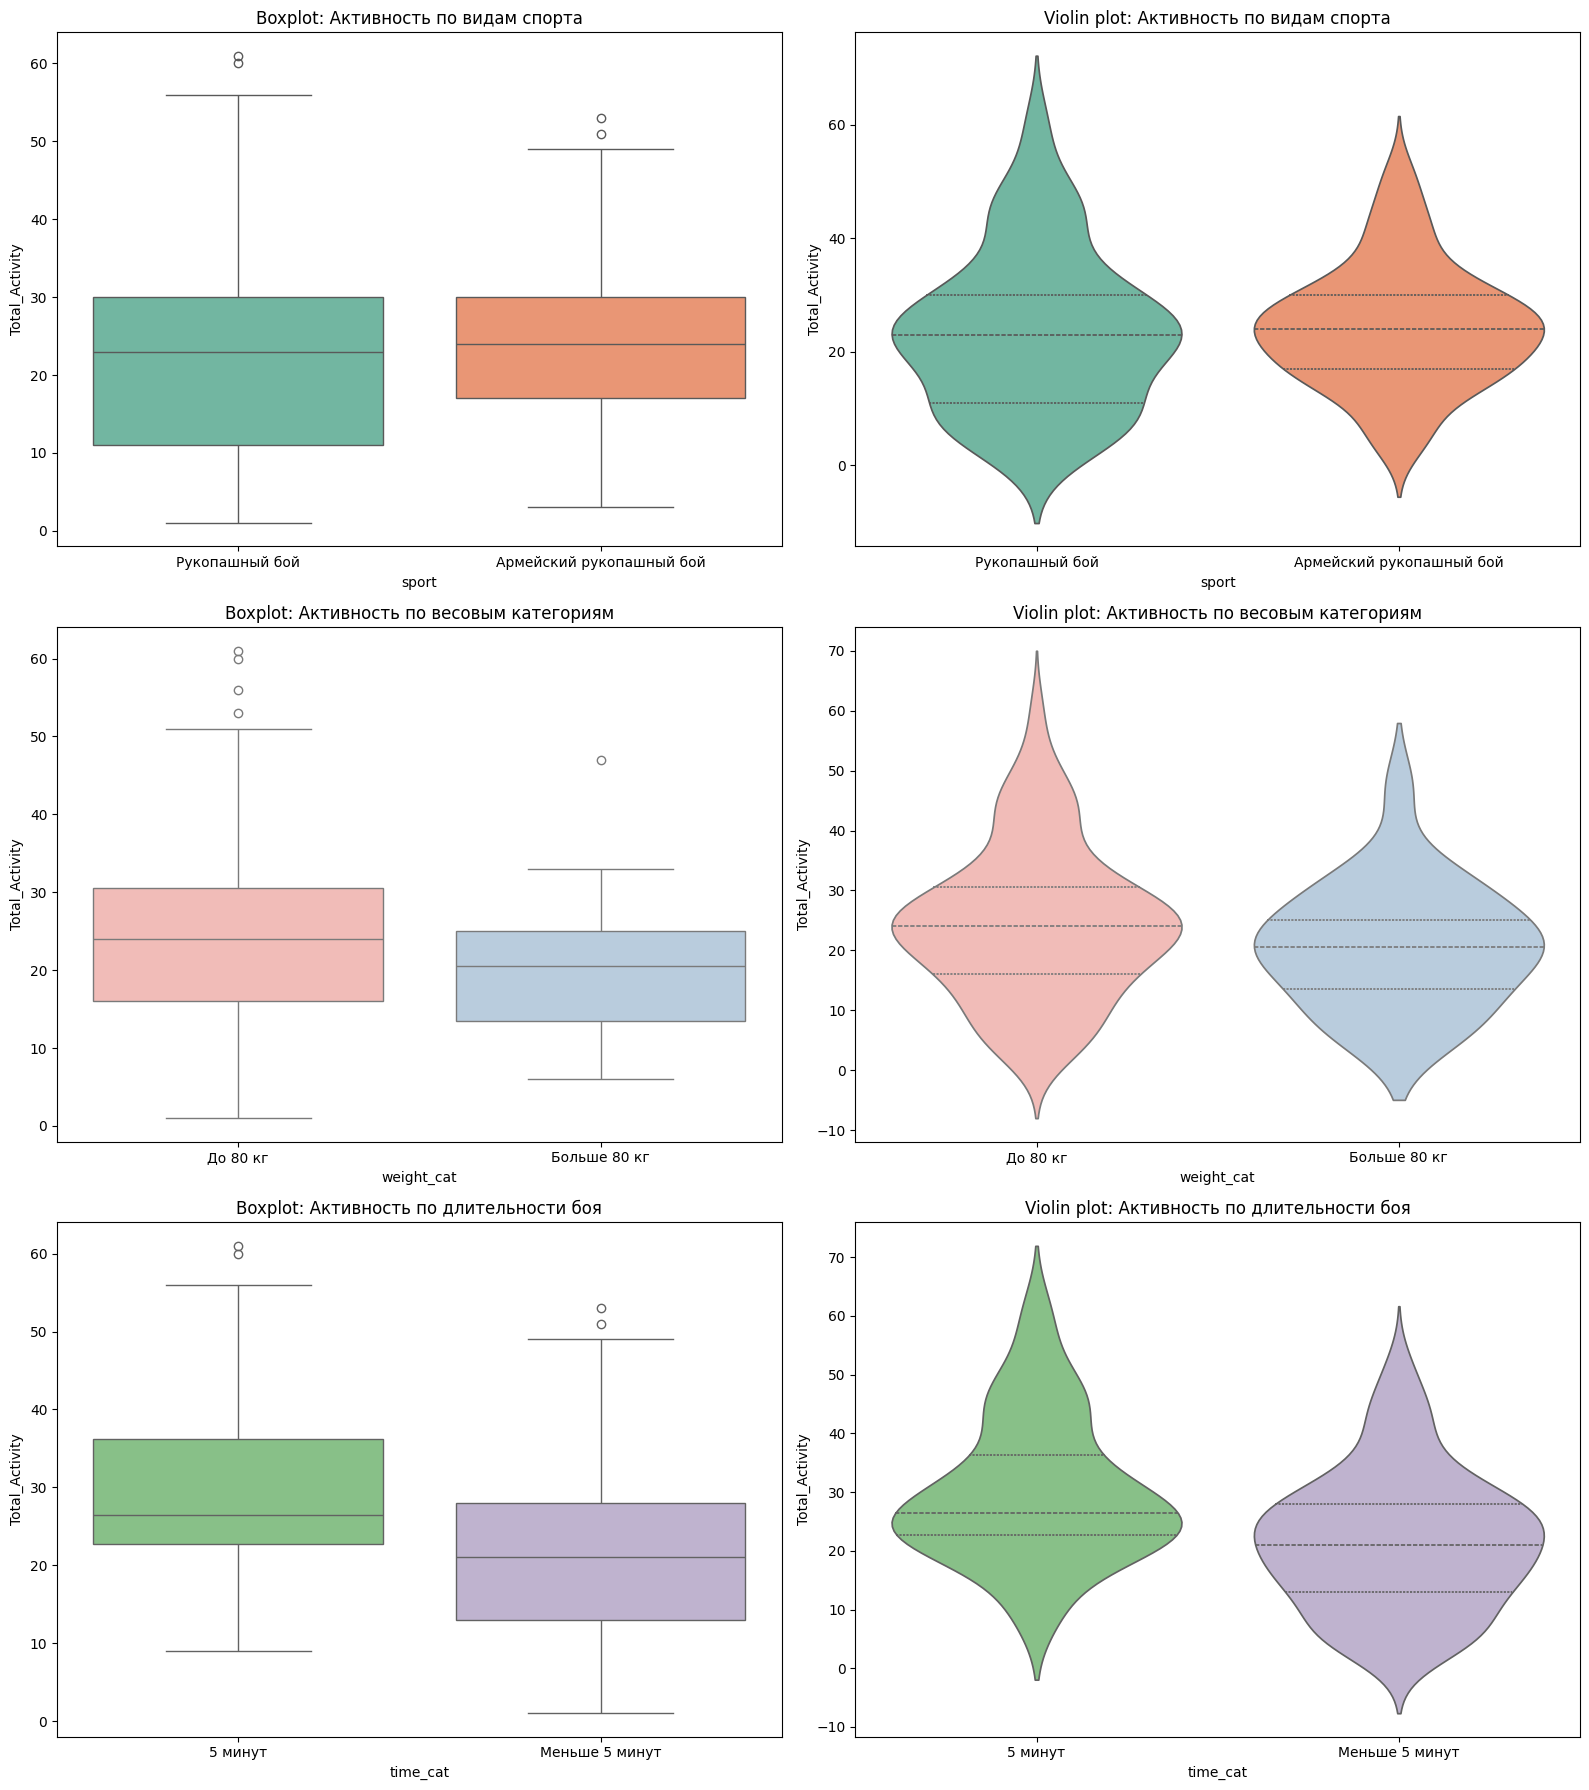


СТАТИСТИЧЕСКАЯ МОДЕЛЬ: Полный датасет (только активность) (N = 197)

Метрики качества модели на тестовой выборке:
Критерий продуктивности  Значение
               Accuracy  0.433333
              Precision  0.437500
                 Recall  0.466667
               F1-Score  0.451613
                ROC-AUC  0.444444

Вклад параметров в успешность боя (отсортировано по силе влияния):
Параметр активности  Коэффициент (Log Odds)  Отношение шансов (Odds Ratio)
                Kt5               -0.542006                       0.581580
                Kt4                0.508380                       1.662595
                Ht4               -0.405394                       0.666714
                Ht2                0.364296                       1.439501
                Kt1                0.313166                       1.367749
                Ht5                0.197721                       1.218623
                Ht3               -0.154303                       0.857012
             

In [13]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, roc_auc_score

# ==========================================
# 1. ЗАГРУЗКА И ПОДГОТОВКА ДАННЫХ
# ==========================================
df = pd.read_excel('/content/vyatkin_Sorevnovatelnaya_deyatelnost_logregressia.xlsx')


ht_cols = [f'Ht{i}' for i in range(1, 6)]
kt_cols = [f'Kt{i}' for i in range(1, 6)]
activity_features = ht_cols + kt_cols

df['Total_Ht'] = df[ht_cols].sum(axis=1)
df['Total_Kt'] = df[kt_cols].sum(axis=1)
df['Total_Activity'] = df['Total_Ht'] + df['Total_Kt']

# Новые категориальные переменные для веса и времени
df['weight_cat'] = np.where(df['weight'] <= 80, 'До 80 кг', 'Больше 80 кг')
df['time_cat'] = np.where(df['time'] == 5, '5 минут', 'Меньше 5 минут')

# ==========================================
# 2. ПОЛНЫЙ СТАТИСТИЧЕСКИЙ АНАЛИЗ (EDA)
# ==========================================
print("--- 2.1. ОПИСАТЕЛЬНАЯ СТАТИСТИКА АКТИВНОСТИ ---")
print(df[activity_features + ['Total_Ht', 'Total_Kt', 'Total_Activity']].describe())

print("\n--- 2.2. ПРОВЕРКА РАСПРЕДЕЛЕНИЙ НА НОРМАЛЬНОСТЬ (Тест Шапиро-Уилка) ---")
for col in ['Total_Ht', 'Total_Kt', 'Total_Activity']:
    stat, p_val = stats.shapiro(df[col].dropna())
    print(f"Признак: {col:15} | Статистика: {stat:.4f} | p-value: {p_val:.4e} -> {'Нормальное' if p_val > 0.05 else 'НЕ нормальное'}")

print("\n--- 2.3. СРАВНЕНИЕ РАСПРЕДЕЛЕНИЙ ПО ГРУППАМ ---")
def compare_groups(data, group_col, target_col):
    groups = data[group_col].unique()
    if len(groups) != 2:
        print(f"Группировка по {group_col} невозможна: ожидалось 2 группы, найдено {len(groups)}")
        return
    g1 = data[data[group_col] == groups[0]][target_col].dropna()
    g2 = data[data[group_col] == groups[1]][target_col].dropna()

    levene_p = stats.levene(g1, g2).pvalue
    norm_p1 = stats.shapiro(g1).pvalue
    norm_p2 = stats.shapiro(g2).pvalue

    if norm_p1 > 0.05 and norm_p2 > 0.05:
        stat, p = stats.ttest_ind(g1, g2, equal_var=(levene_p > 0.05))
        test_name = "T-test"
    else:
        stat, p = stats.mannwhitneyu(g1, g2, alternative='two-sided')
        test_name = "Mann-Whitney U"

    print(f"Различия по {group_col:10} ({groups[0]} vs {groups[1]}) для {target_col}:")
    print(f"  Тест: {test_name} | p-value: {p:.4e} -> {'Различия ЗНАЧИМЫ' if p < 0.05 else 'Различия НЕ значимы'}")

compare_groups(df, 'sport', 'Total_Activity')
compare_groups(df, 'weight_cat', 'Total_Activity')
compare_groups(df, 'time_cat', 'Total_Activity')

# ==========================================
# 3. РАСШИРЕННАЯ ВИЗУАЛИЗАЦИЯ
# ==========================================
fig, axes = plt.subplots(3, 2, figsize=(16, 18))

# Группа 1: Вид спорта
sns.boxplot(data=df, x='sport', y='Total_Activity', palette='Set2', ax=axes[0, 0])
axes[0, 0].set_title('Boxplot: Активность по видам спорта')
sns.violinplot(data=df, x='sport', y='Total_Activity', palette='Set2', inner='quartile', ax=axes[0, 1])
axes[0, 1].set_title('Violin plot: Активность по видам спорта')

# Группа 2: Весовые категории
sns.boxplot(data=df, x='weight_cat', y='Total_Activity', palette='Pastel1', ax=axes[1, 0])
axes[1, 0].set_title('Boxplot: Активность по весовым категориям')
sns.violinplot(data=df, x='weight_cat', y='Total_Activity', palette='Pastel1', inner='quartile', ax=axes[1, 1])
axes[1, 1].set_title('Violin plot: Активность по весовым категориям')

# Группа 3: Временные категории (Новая визуализация)
sns.boxplot(data=df, x='time_cat', y='Total_Activity', palette='Accent', ax=axes[2, 0])
axes[2, 0].set_title('Boxplot: Активность по длительности боя')
sns.violinplot(data=df, x='time_cat', y='Total_Activity', palette='Accent', inner='quartile', ax=axes[2, 1])
axes[2, 1].set_title('Violin plot: Активность по длительности боя')

plt.tight_layout()
plt.show()

# ==========================================
# 4. МАТЕМАТИЧЕСКОЕ МОДЕЛИРОВАНИЕ И ОЦЕНКА ВКЛАДА
# ==========================================
def run_logistic_regression(data, title):
    print(f"\n{'='*50}\nСТАТИСТИЧЕСКАЯ МОДЕЛЬ: {title} (N = {len(data)})\n{'='*50}")

    # Исключаем нерелевантные или пустые признаки для коротких боев
    # Если бой длился меньше 5 минут, на 5-й минуте ударов гарантированно 0,
    # что вызовет нулевую дисперсию. Отсекаем такие колонки.
    valid_features = [col for col in activity_features if data[col].std() > 0]

    X = data[valid_features]
    y = data['result']

    if len(y.unique()) < 2:
        print("Построение модели невозможно: подвыборка содержит только один класс исхода.")
        return

    X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

    scaler = StandardScaler()
    X_train_scaled = scaler.fit_transform(X_train)
    X_test_scaled = scaler.transform(X_test)

    model = LogisticRegression(max_iter=1000)
    model.fit(X_train_scaled, y_train)

    y_pred = model.predict(X_test_scaled)
    y_proba = model.predict_proba(X_test_scaled)[:, 1]

    metrics_df = pd.DataFrame({
        'Критерий продуктивности': ['Accuracy', 'Precision', 'Recall', 'F1-Score', 'ROC-AUC'],
        'Значение': [
            accuracy_score(y_test, y_pred),
            precision_score(y_test, y_pred),
            recall_score(y_test, y_pred),
            f1_score(y_test, y_pred),
            roc_auc_score(y_test, y_proba)
        ]
    })
    print("\nМетрики качества модели на тестовой выборке:")
    print(metrics_df.to_string(index=False))

    importance = pd.DataFrame({
        'Параметр активности': valid_features,
        'Коэффициент (Log Odds)': model.coef_[0],
        'Отношение шансов (Odds Ratio)': np.exp(model.coef_[0]),
        'Абсолютное влияние': np.abs(model.coef_[0])
    }).sort_values(by='Абсолютное влияние', ascending=False)

    print("\nВклад параметров в успешность боя (отсортировано по силе влияния):")
    print(importance[['Параметр активности', 'Коэффициент (Log Odds)', 'Отношение шансов (Odds Ratio)']].to_string(index=False))

# Запуск полного перечня из 7 конфигураций моделей
run_logistic_regression(df, "Полный датасет (только активность)")
run_logistic_regression(df[df['sport'] == 'Рукопашный бой'], "Рукопашный бой (РБ)")
run_logistic_regression(df[df['sport'] == 'Армейский рукопашный бой'], "Армейский рукопашный бой (АРБ)")
run_logistic_regression(df[df['weight_cat'] == 'До 80 кг'], "Весовая категория до 80 кг")
run_logistic_regression(df[df['weight_cat'] == 'Больше 80 кг'], "Весовая категория более 80 кг")
run_logistic_regression(df[df['time_cat'] == '5 минут'], "Бои полной длительности (5 минут)")
run_logistic_regression(df[df['time_cat'] == 'Меньше 5 минут'], "Бои укороченной длительности (< 5 минут)")


/tmp/ipykernel_1260/2927853233.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='sport', y='Total_Activity', palette='Set2', ax=axes[0])
/tmp/ipykernel_1260/2927853233.py:16: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='weight_cat', y='Total_Activity', palette='Pastel1', ax=axes[1])
/tmp/ipykernel_1260/2927853233.py:23: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df, x='time_cat', y='Total_Activity', palette='Accent', ax=axes[2])


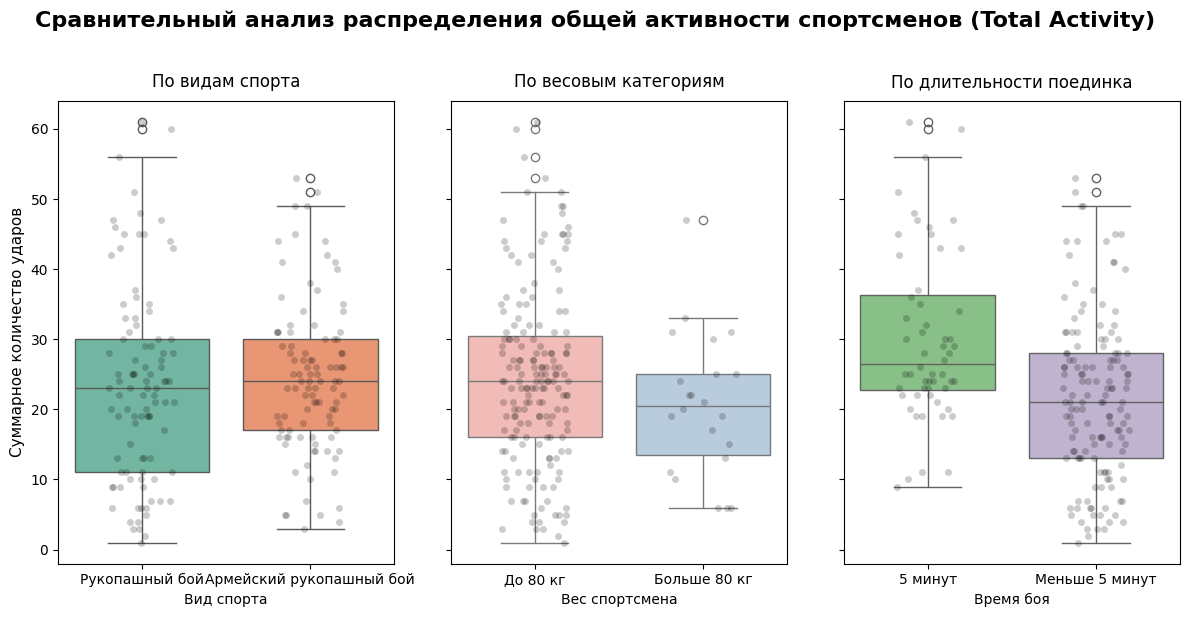

In [15]:
# ==========================================
# 3. МОДИФИЦИРОВАННАЯ ВИЗУАЛИЗАЦИЯ (3 БОКС ПЛОТА В РЯД)
# ==========================================
# Создаем одну общую фигуру, состоящую из 1 строки и 3 колонок
fig, axes = plt.subplots(1, 3, figsize=(12, 6), sharey=True)
fig.suptitle('Сравнительный анализ распределения общей активности спортсменов (Total Activity)', fontsize=16, fontweight='bold', y=1.02)

# График 1: Разделение по видам спорта
sns.boxplot(data=df, x='sport', y='Total_Activity', palette='Set2', ax=axes[0])
sns.stripplot(data=df, x='sport', y='Total_Activity', color='black', alpha=0.2, jitter=0.2, ax=axes[0])
axes[0].set_title('По видам спорта', fontsize=12, pad=10)
axes[0].set_xlabel('Вид спорта', fontsize=10)
axes[0].set_ylabel('Суммарное количество ударов', fontsize=11)

# График 2: Разделение по весовым категориям
sns.boxplot(data=df, x='weight_cat', y='Total_Activity', palette='Pastel1', ax=axes[1])
sns.stripplot(data=df, x='weight_cat', y='Total_Activity', color='black', alpha=0.2, jitter=0.2, ax=axes[1])
axes[1].set_title('По весовым категориям', fontsize=12, pad=10)
axes[1].set_xlabel('Вес спортсмена', fontsize=10)
axes[1].set_ylabel('') # Скрываем дублирующую подпись оси Y

# График 3: Разделение по длительности боя
sns.boxplot(data=df, x='time_cat', y='Total_Activity', palette='Accent', ax=axes[2])
sns.stripplot(data=df, x='time_cat', y='Total_Activity', color='black', alpha=0.2, jitter=0.2, ax=axes[2])
axes[2].set_title('По длительности поединка', fontsize=12, pad=10)
axes[2].set_xlabel('Время боя', fontsize=10)
axes[2].set_ylabel('') # Скрываем дублирующую подпись оси Y

# Оптимизируем расположение элементов диаграммы
plt.tight_layout()
plt.show()
